<div> <img src="https://upload.wikimedia.org/wikipedia/commons/5/55/MIDAS_Information_Technology_Co.%2C_Ltd._LOGO.png" width="200"/> </div>

# ARCH BRIDGE

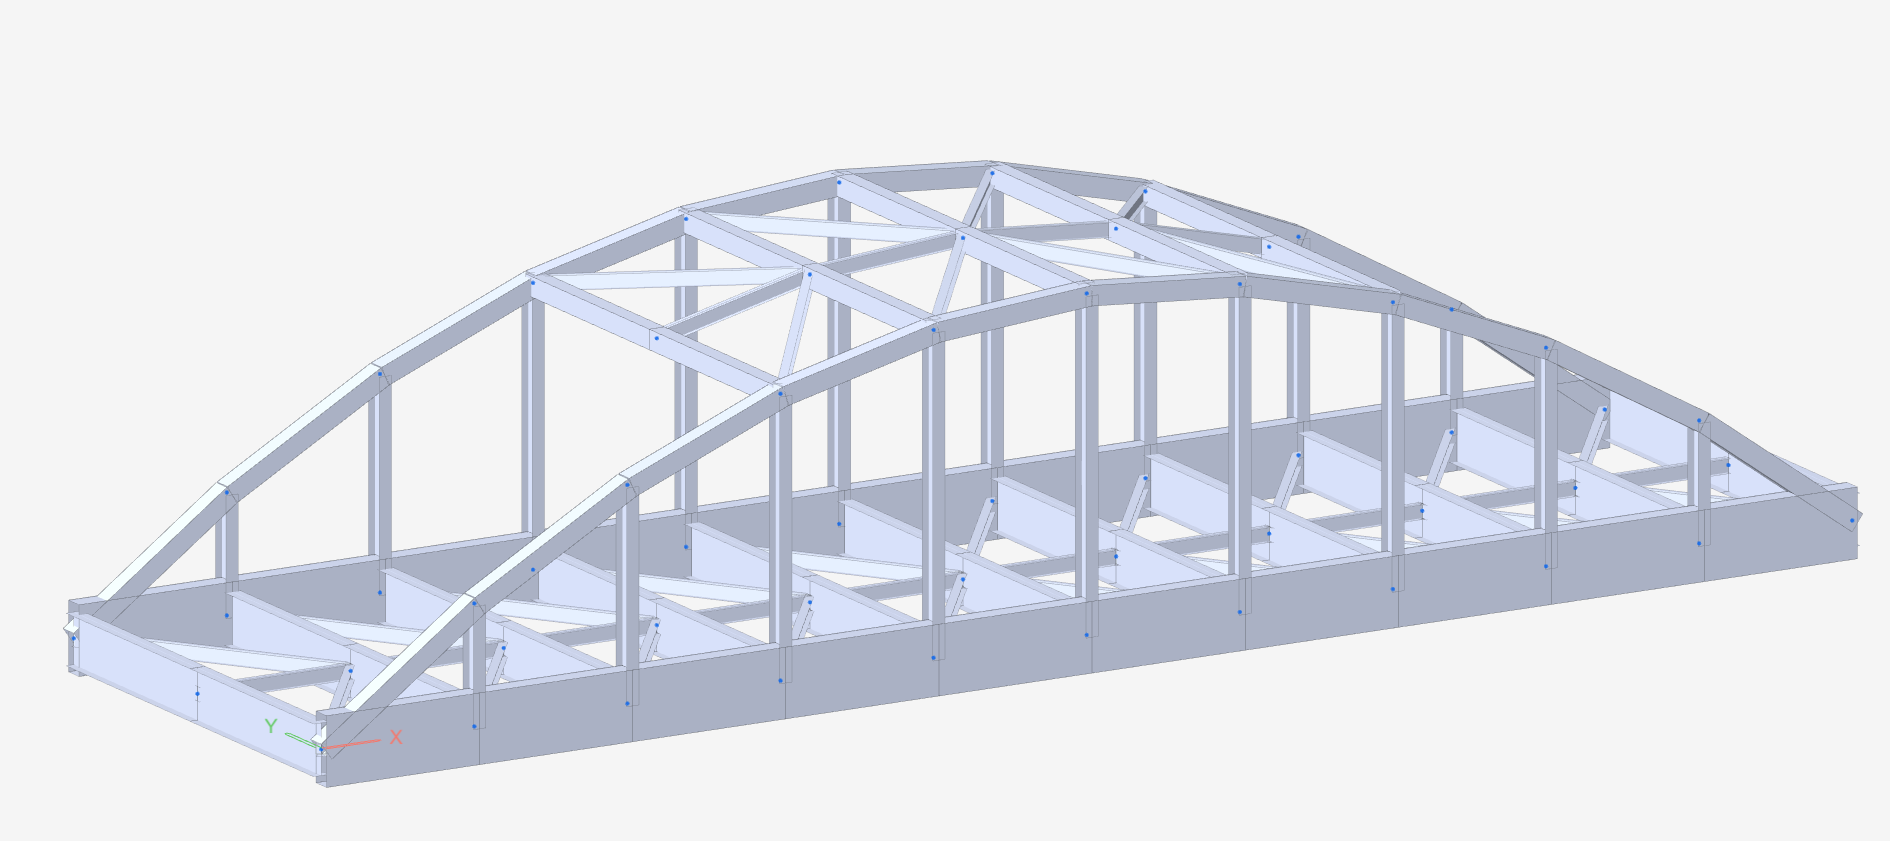

## 1. Importing Library

In [ ]:
! pip install midas_civil

## 2. Setting Up

In [ ]:
from midas_civil import *
import math
MAPI_KEY("xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx")
MAPI_BASEURL.autoURL()
Model.units('N','M')


╭────────────────────────────────────────────────────────────────────────────────────╮
│                      MIDAS CIVIL-NX PYTHON LIBRARY v1.6.1  🐍                      │
╰────────────────────────────────────────────────────────────────────────────────────╯


╭─ 🔔  ──────────────────────────────────────────────────────────────────────────────╮
│             Connected to MIDAS CIVIL NX 2025 (v2.2)            SERVER : INDIA   🟢 │
│             USER : bruhathi          COMPANY : midas                               │
╰────────────────────────────────────────────────────────────────────────────────────╯



## 3. Modelling

Inputs
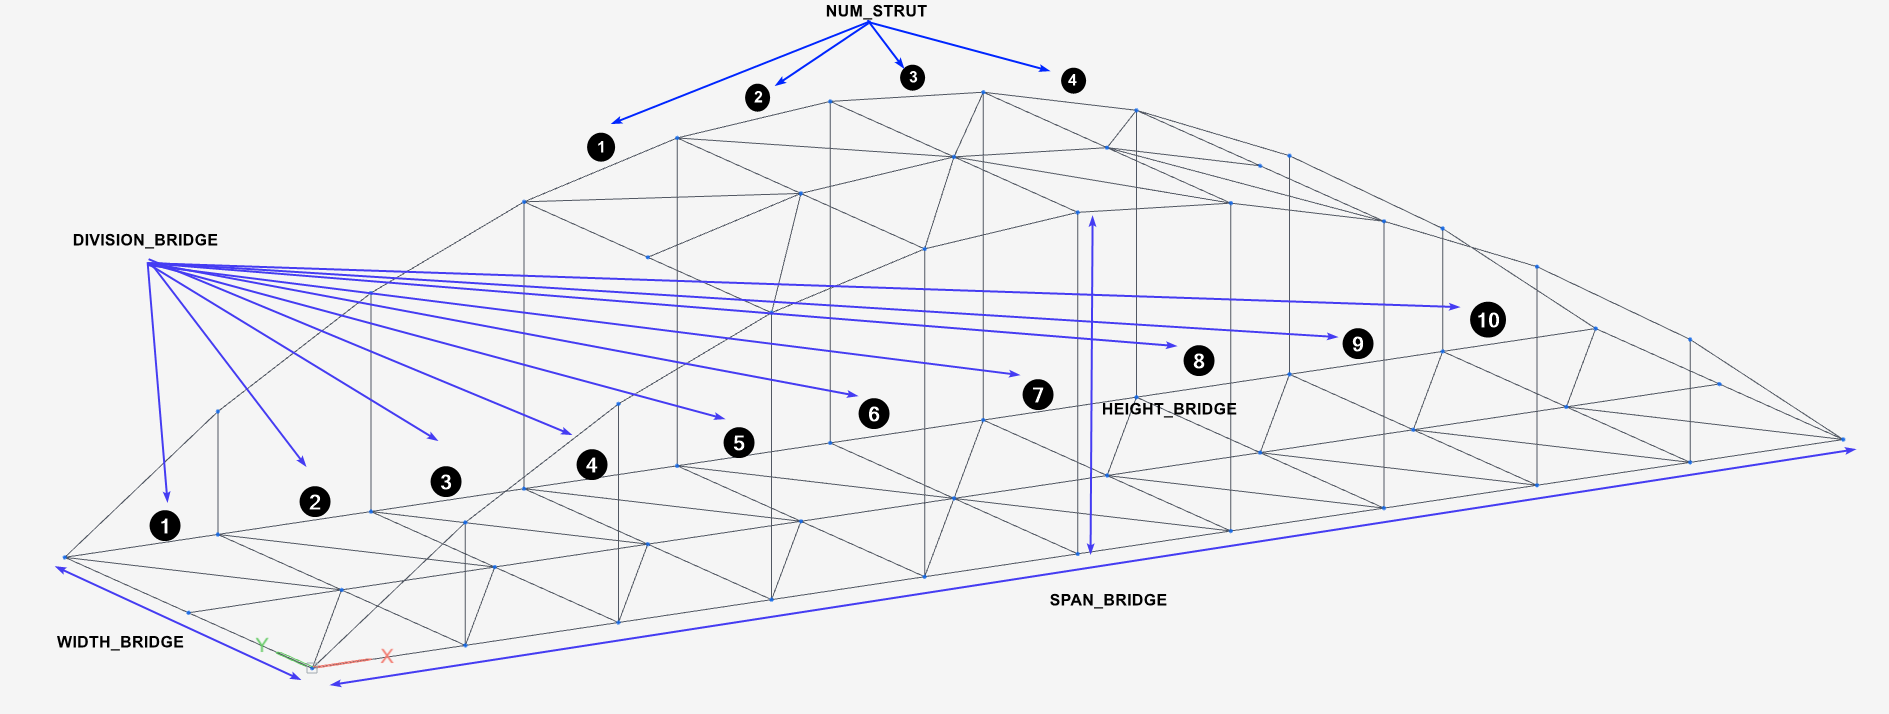

In [ ]:
SPAN_BRIDGE = 50
HEIGHT_BRIDGE = 10
WIDTH_BRIDGE = 14
DIVISION_BRIDGE = 10 #EVEN
NUM_STRUT = 4 #Even

### A. Material Properties

In [2]:
Material.STEEL('A36','ASTM(S)','A36',id=1)
Material.STEEL('A572-50','ASTM(S)','A572-50',id=2)
Material.create()

### B. Section Properties

In [3]:
Section.DBUSER('Main Girder','B',[2.1,0.6,0.01,0.01],id=1)
Section.DBUSER('Cross Beam','H',[1.54,0.5,0.014,0.027],id=2)
Section.DBUSER('Arch Rib','B',[0.6,0.6,0.016,0.014],id=3)
Section.DBUSER('Hanger','H',[0.6,0.4,0.012,0.016],id=4)
Section.DBUSER('Strut','B',[0.6,0.5,0.01,0.014],id=5)
Section.DBUSER('Bracing','H',[0.43,0.26,0.015,0.025],id=6)
Section.create()

### C. Element Generation

Main Girder elements are created along X-direction

In [5]:
Element.Beam.SE((0,0,0),(SPAN_BRIDGE,0,0),DIVISION_BRIDGE,2,1,group='#MainGirder_R')
Element.Beam.SE((0,WIDTH_BRIDGE,0),(SPAN_BRIDGE,WIDTH_BRIDGE,0),DIVISION_BRIDGE,2,1,group='#MainGirder_L')

Beam Elements along the arch are created

In [6]:
Element.Beam.PLine([(0,0,0),(SPAN_BRIDGE*0.5,0,HEIGHT_BRIDGE),(SPAN_BRIDGE,0,0)],DIVISION_BRIDGE,2,div_axis='X',mat=2,sect=3,group='#Arch_R')
Element.Beam.PLine([(0,WIDTH_BRIDGE,0),(SPAN_BRIDGE*0.5,WIDTH_BRIDGE,HEIGHT_BRIDGE),(SPAN_BRIDGE,WIDTH_BRIDGE,0)],DIVISION_BRIDGE,2,div_axis='X',mat=2,sect=3,group='#Arch_L')

Creates cross beams connecting the two main girders

In [7]:
for i in range(DIVISION_BRIDGE+1):
    Element.Beam.SE(nodesInGroup('#MainGirder_R',output='NODE')[i],nodesInGroup('#MainGirder_L',output='NODE')[i],2,2,2,group=[f'#Cross Beam_{i+1}','Cross Beam'])

Creates Hangers connecting the arch beams and the main girders

In [8]:
for i in range(DIVISION_BRIDGE-1):
    Element.Beam(nodesInGroup('#Arch_R')[i+1],nodesInGroup('#MainGirder_R')[i+1],2,4,90,group=['#Hanger_R'])
    Element.Beam(nodesInGroup('#Arch_L')[i+1],nodesInGroup('#MainGirder_L')[i+1],2,4,90,group=['#Hanger_L'])

Creates struts connecting the arch elements

In [9]:
idx = (DIVISION_BRIDGE-NUM_STRUT)//3+1
for i in range(NUM_STRUT+1):
    Element.Beam.SE(nodesInGroup('#Arch_R',output='NODE')[idx+i],nodesInGroup('#Arch_L',output='NODE')[idx+i],2,1,5,group=[f'#Strut_{i+1}','Strut'])

Creates bracings connecting the struts at the top

In [10]:
for i in range(NUM_STRUT):
    Element.Beam(nodesInGroup(f'#Strut_{i+1}')[1],nodesInGroup(f'#Strut_{i+2}')[1],1,6)

for i in range(NUM_STRUT//2):
    Element.Beam(nodesInGroup(f'#Strut_{i+1}')[0],nodesInGroup(f'#Strut_{i+2}')[1],1,6)
    Element.Beam(nodesInGroup(f'#Strut_{i+1}')[2],nodesInGroup(f'#Strut_{i+2}')[1],1,6)

    Element.Beam(nodesInGroup(f'#Strut_{NUM_STRUT-i+1}')[0],nodesInGroup(f'#Strut_{NUM_STRUT-i}')[1],1,6)
    Element.Beam(nodesInGroup(f'#Strut_{NUM_STRUT-i+1}')[2],nodesInGroup(f'#Strut_{NUM_STRUT-i}')[1],1,6)

Creates bracings in the bottom connecting the cross beams

In [11]:
for i in range(DIVISION_BRIDGE):
    Element.Beam(nodesInGroup(f'#Cross Beam_{i+1}')[1],nodesInGroup(f'#Cross Beam_{i+2}')[1],1,6)

for i in range(DIVISION_BRIDGE//2):
    Element.Beam(nodesInGroup(f'#Cross Beam_{i+1}')[0],nodesInGroup(f'#Cross Beam_{i+2}')[1],1,6)
    Element.Beam(nodesInGroup(f'#Cross Beam_{i+1}')[2],nodesInGroup(f'#Cross Beam_{i+2}')[1],1,6)

    Element.Beam(nodesInGroup(f'#Cross Beam_{DIVISION_BRIDGE-i+1}')[0],nodesInGroup(f'#Cross Beam_{DIVISION_BRIDGE-i}')[1],1,6)
    Element.Beam(nodesInGroup(f'#Cross Beam_{DIVISION_BRIDGE-i+1}')[2],nodesInGroup(f'#Cross Beam_{DIVISION_BRIDGE-i}')[1],1,6)

Generates nodes and elements in MIDAS CIVIL NX

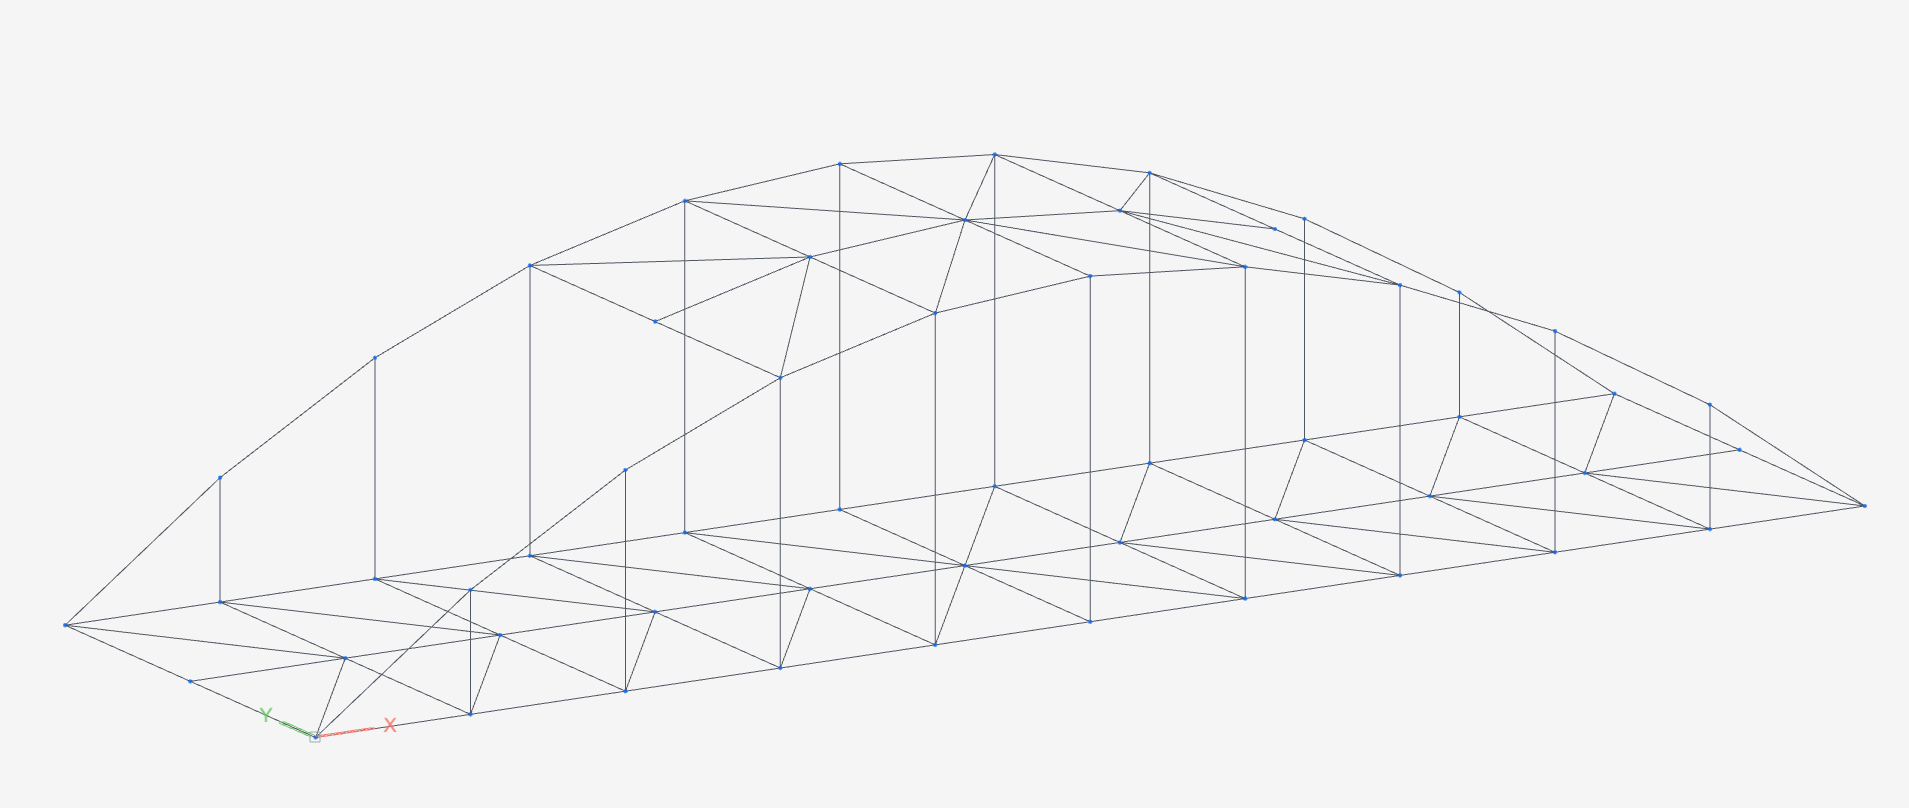

In [12]:
Node.create()
Element.create()

### D. Supports

Boundary conditions and beam end releases are assigned 
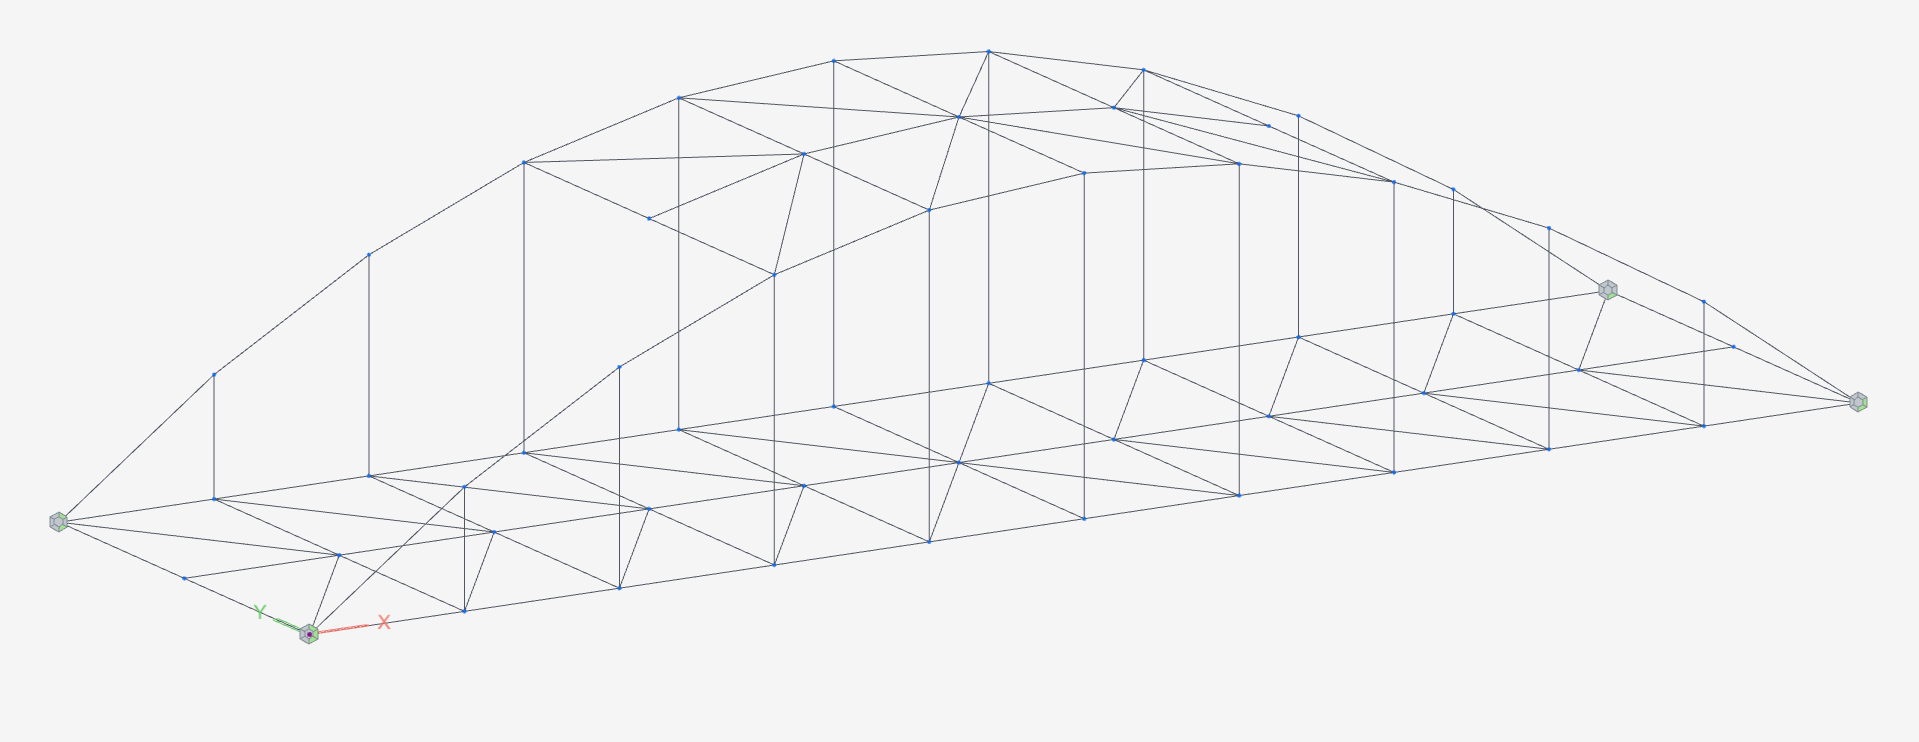

In [13]:
Boundary.Support(Node(0,0,0).ID,"1110000")
Boundary.Support(Node(SPAN_BRIDGE,0,0).ID,"0110000")
Boundary.Support(Node(0,WIDTH_BRIDGE,0).ID,"1010000")
Boundary.Support(Node(SPAN_BRIDGE,WIDTH_BRIDGE,0).ID,"0010000")

for elmID in elemsInGroup(['#Hanger_R','#Hanger_L']):
    Boundary.BeamEndRelease(elmID,Mz_I=0,Mz_J=0)

for elm in Element.elements:
    if elm.SECT == 6 :
        Boundary.BeamEndRelease(elm.ID,My_I=0,Mz_I=0,My_J=0,Mz_J=0)

for i in range(DIVISION_BRIDGE+1):
    _CrossBeam = elemsInGroup(f'#Cross Beam_{i+1}')
    Boundary.BeamEndRelease(_CrossBeam[0],My_I=0,Mz_I=0)
    Boundary.BeamEndRelease(_CrossBeam[1],My_J=0,Mz_J=0)

Boundary.create()

### E. Loading

Creates Static Load Cases

In [14]:
Load_Case("D","Dead Load")
Load_Case("L","Side Walk Load")
Load_Case.create()

Applies Dead Load to the structure
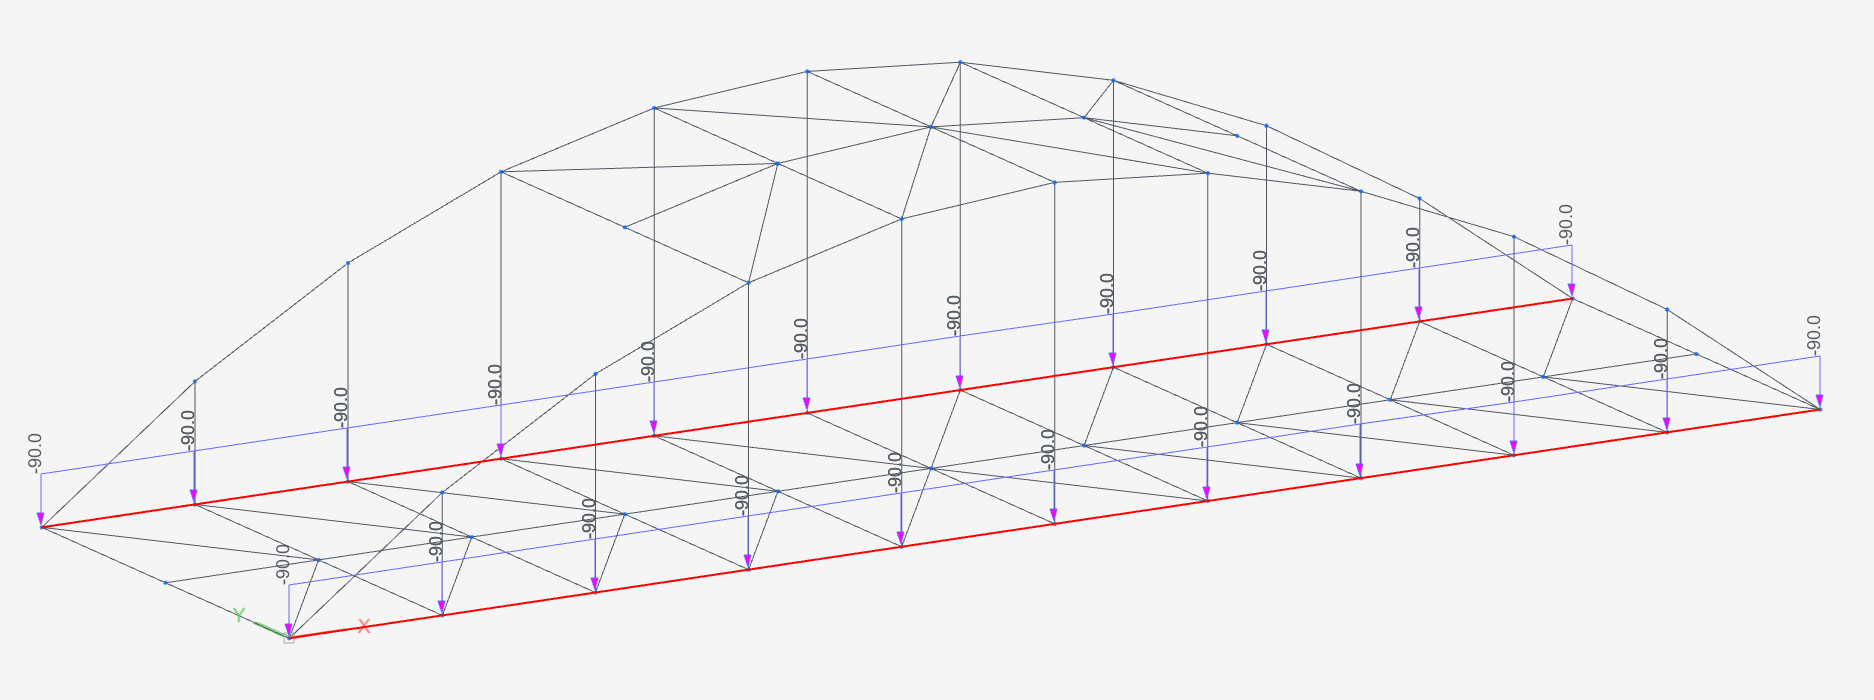

In [15]:
Load.Beam(elemsInGroup(['#MainGirder_R','#MainGirder_L']),'Dead Load','',-90,'GZ')
Load.Beam.create()

Applies Side Walk Load to the structure
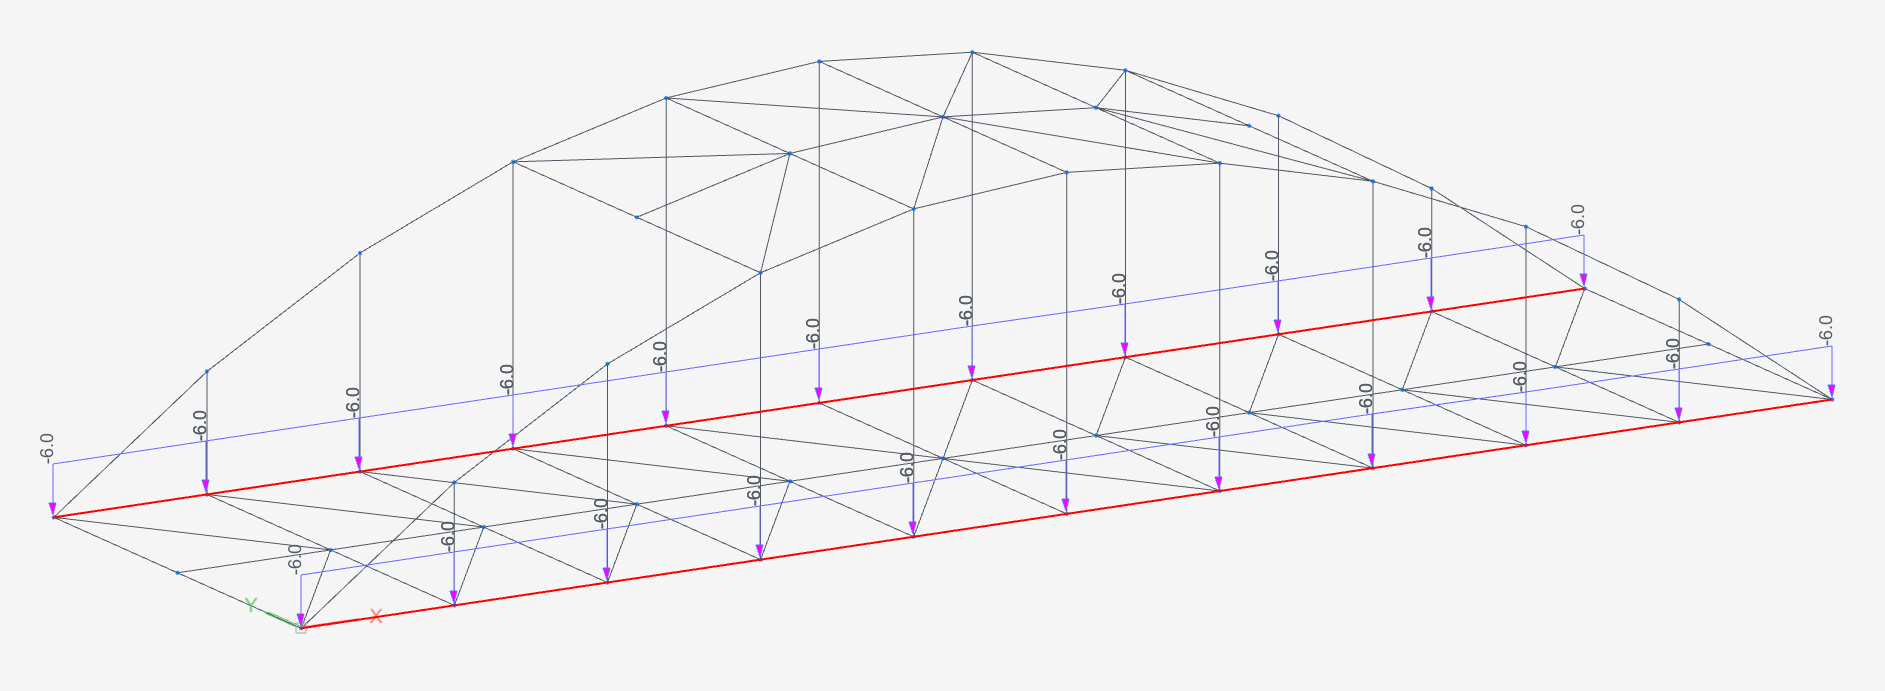

In [16]:
Load.Beam(elemsInGroup(['#MainGirder_R','#MainGirder_L']),'Side Walk Load','',-6,'GZ')
Load.Beam.create()